In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as mlt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_squared_error,r2_score
from sklearn.linear_model import Ridge






In [5]:
#loading the datasets
data=fetch_california_housing(as_frame=True)
#combine input features and target variable
df=pd.concat([data.data,data.target.rename("HousePrice")],axis=1)
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
#seperate the input features and target variable
X=df.drop("HousePrice", axis=1)
y=df["HousePrice"]
#display the shapes
print("Features shape=",X.shape)
print("Target Shape=",y.shape)




Features shape= (20640, 8)
Target Shape= (20640,)


In [7]:
#splitting the dataset into training and testing
X_train, X_test,y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)

#display the shapes
print("X_train =",X_train.shape)
print("X_test =",X_test.shape)
print("y_train =",y_train.shape)
print("y_test =",y_test.shape)



X_train = (16512, 8)
X_test = (4128, 8)
y_train = (16512,)
y_test = (4128,)


In [8]:
#create the standardscaler object
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
#transform the testing data
X_test_scaled=scaler.transform(X_test)
#Display the shapes
print("Scaled training data=",X_train_scaled.shape)
print("Scaled test data=",X_test_scaled.shape)



Scaled training data= (16512, 8)
Scaled test data= (4128, 8)


In [9]:
#linear regression model
lr_model=LinearRegression()
lr_model.fit(X_train_scaled,y_train)
print("Linear regression model trained successfully")


Linear regression model trained successfully


In [10]:
#making predictions using the lr trained model
lr_predictions=lr_model.predict(X_test_scaled)
#display first 5 predicytions
print("Fisrt 5 predicted house prices")
print(lr_predictions[:5])



Fisrt 5 predicted house prices
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [11]:
#calculate the mean absolute error
mae=np.mean(np.abs(y_test-lr_predictions))
#caculate rmse
rmse=np.sqrt(mean_squared_error(y_test,lr_predictions))
#calculate r2 square
r2=r2_score(y_test,lr_predictions)

#display the evaluated results
print("Linear regression model evaluation")
print("MAE=",mae)
print("RMSE=",rmse)
print("R2 Score:", r2)


Linear regression model evaluation
MAE= 0.5332001304956566
RMSE= 0.7455813830127763
R2 Score: 0.575787706032451


In [18]:
#create ridge regression
from sklearn.linear_model import Ridge
ridge_model=Ridge(alpha=1.0)

In [23]:
#train the ride-regression model
ridge_model.fit(X_train,y_train)
print("Ridge regression model trained successfully")


Ridge regression model trained successfully


In [26]:
# Generate predictions
ridge_predictions = ridge_model.predict(X_test)
# Calculate MAE
ridge_mae = np.mean(np.abs(y_test - ridge_predictions))

# Calculate RMSE
ridge_rmse = np.sqrt(mean_squared_error(y_test,ridge_predictions))

# Calculate R2 Score
ridge_r2 = r2_score(y_test, ridge_predictions)

# Display evaluation results
print("Ridge Regression Model Evaluation")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression Model Evaluation
MAE: 0.5332039182571146
RMSE: 0.7455222779992705
R2 Score: 0.5758549611440122


In [27]:
#decision tree regression
dt_model=DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train,y_train)
print("Decision tree modeled successfully")


Decision tree modeled successfully


In [28]:
dt_predictions=dt_model.predict(X_test)
print("First 5 Decision tree predictions ")
print(dt_predictions[:5])


First 5 Decision tree predictions 
[0.414   1.203   5.00001 2.17    2.257  ]


In [29]:
dt_mae=np.mean(np.abs(y_test-dt_predictions))
dt_rmse=np.sqrt(mean_squared_error(y_test,dt_predictions))
dt_r2=r2_score(y_test,dt_predictions)
print("Decision tree model evaluation")
print("MAE=",dt_mae)
print("RMSE=",dt_rmse)
print("R2 Score=",dt_r2)


Decision tree model evaluation
MAE= 0.4541711942829458
RMSE= 0.7030332265476953
R2 Score= 0.622823312540521


In [30]:
# Create a dictionary to store model evaluation results

results = {
    "Model": ["Linear Regression", "Ridge Regression", "Decision Tree"],
    "MAE": [mae, ridge_mae, dt_mae],
    "RMSE": [rmse, ridge_rmse, dt_rmse],
    "R2 Score": [r2, ridge_r2, dt_r2]
}

# Convert dictionary into DataFrame
results_df = pd.DataFrame(results)

# Display comparison table
results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.533200,0.745581,0.575788
1,Ridge Regression,0.533204,0.745522,0.575855
2,Decision Tree,0.454171,0.703033,0.622823


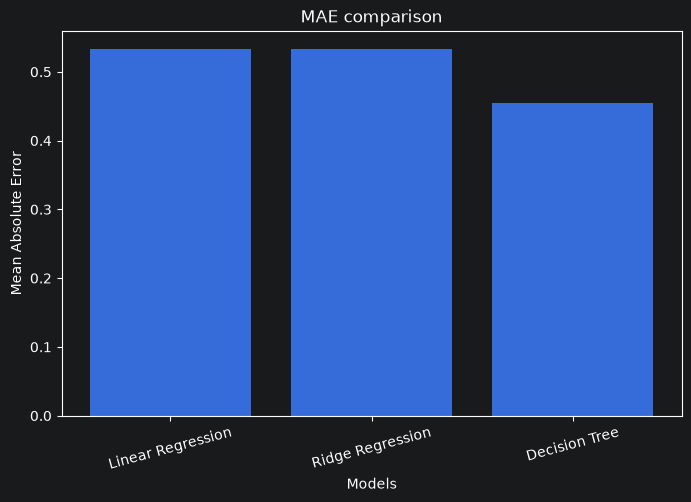

In [34]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"],results_df["MAE"])
plt.title("MAE comparison")
plt.xlabel("Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)

plt.show()


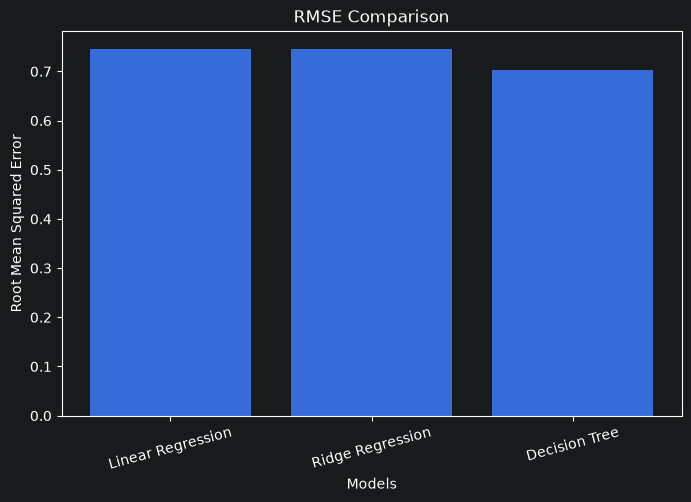

In [35]:
plt.figure(figsize=(8,5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("RMSE Comparison")
plt.xlabel("Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=15)

plt.show()

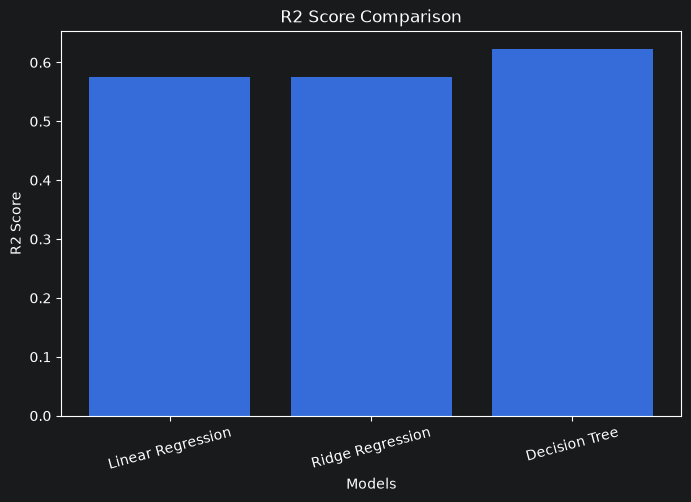

In [36]:
plt.figure(figsize=(8,5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("R2 Score Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)

plt.show()

In [37]:
best_model = results_df.loc[results_df["R2 Score"].idxmax()]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model       Decision Tree
MAE              0.454171
RMSE             0.703033
R2 Score         0.622823
Name: 2, dtype: object


In [38]:
results_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [49]:
if best_model["Model"]=="Linear Regression":
    best_predictions=y_pred
elif best_model["Model"] == "Ridge Regression":
    best_predictions = ridge_predictions
else:
    best_predictions = dt_predictions



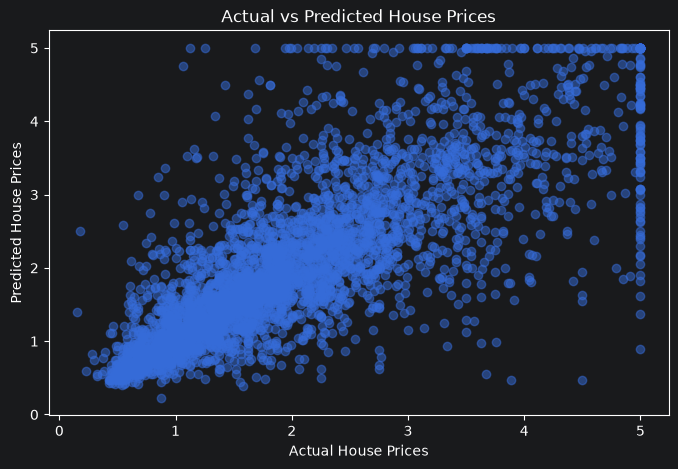

In [40]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, best_predictions, alpha=0.5)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [50]:
if best_model["Model"] == "Linear Regression":
    final_model = model

elif best_model["Model"] == "Ridge Regression":
    final_model = ridge_model

else:
    final_model = dt_model

print("Best model selected successfully!")

Best model selected successfully!


In [42]:
import pickle
with open("best_house_price_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

print("Best model saved successfully!")

Best model saved successfully!


In [43]:
with open("best_house_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [45]:
sample_predictions = loaded_model.predict(X_test[:5])

print("Predicted House Prices:")
print(sample_predictions)

Predicted House Prices:
[0.414   1.203   5.00001 2.17    2.257  ]


In [46]:
print("FINAL MODEL PERFORMANCE")
print("------------------------")

print("Best Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

FINAL MODEL PERFORMANCE
------------------------
Best Model: Decision Tree
MAE: 0.4541711942829458
RMSE: 0.7030332265476953
R2 Score: 0.622823312540521


In [47]:
comparison = pd.DataFrame({
    "Actual Price": y_test[:5].values,
    "Predicted Price": sample_predictions
})

print(comparison)

   Actual Price  Predicted Price
0       0.47700          0.41400
1       0.45800          1.20300
2       5.00001          5.00001
3       2.18600          2.17000
4       2.78000          2.25700


In [48]:
comparison.to_csv("prediction_comparison.csv", index=False)

print("Prediction comparison saved successfully!")

Prediction comparison saved successfully!
